# Visualización de datos con Matplotlib y Seaborn
## Análisis del conjunto de datos (propinas en un restaurante)

**Objetivo:** explorar el dataset de Seaborn y construir cuatro visualizaciones (categórica, numérica, temporal y adicional) aplicando principios de diseño visual y percepción humana.

**Descripción del dataset:** contiene 244 cuentas de un restaurante registradas por un mesero, con el monto de la cuenta, la propina, el sexo de quien pagó, si fumaba, el día, el turno (almuerzo/cena) y el tamaño del grupo.

## 1. Carga y exploración del conjunto de datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset público de Seaborn
tips = sns.load_dataset("tips")
print("Dimensiones (filas, columnas):", tips.shape)
tips.head()

Dimensiones (filas, columnas): (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
# Estructura, tipos de datos y valores nulos
tips.info()
print("\nValores nulos por columna:")
print(tips.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Valores nulos por columna:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [ ]:
# Estadísticos descriptivos de las variables numéricas
tips.describe().round(2)

,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


In [ ]:
# Estadísticos de las variables categóricas
tips.describe(include=["category", "object"])

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [ ]:
# Frecuencia de cada categoría
for col in ["sex", "smoker", "day", "time"]:
    print(tips[col].value_counts(), "\n")

sex
Male      157
Female     87
Name: count, dtype: int64 

smoker
No     151
Yes     93
Name: count, dtype: int64 

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64 

time
Dinner    176
Lunch      68
Name: count, dtype: int64 



### Análisis de las columnas y su uso en los gráficos

| Columna | Tipo | Uso previsto |
|---|---|---|
| `total_bill` | Numérica continua | Eje de dispersión, distribución, ingresos en el tiempo |
| `tip` | Numérica continua | Eje de dispersión, cálculo de porcentaje de propina |
| `size` | Numérica discreta | Tamaño del grupo (codificación por tamaño/color) |
| `day` | Categórica | Gráfico de barras y boxplot |
| `time` | Categórica (2 niveles) | Comparación almuerzo vs. cena |
| `smoker` | Categórica (2 niveles) | Codificación por color en la dispersión |
| `sex` | Categórica (2 niveles) | Segmentación opcional |

no hay valores nulos; la cuenta promedio ronda los 19.8 USD y la propina promedio los 3.0 USD. El dataset **no tiene información temporal**, por lo que se **simulará una columna de fechas**.

In [ ]:
# Variable derivada: porcentaje de propina respecto a la cuenta
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100

# Orden lógico de los días (para que los gráficos no salgan en orden alfabético/aleatorio)
orden_dias = ["Thur", "Fri", "Sat", "Sun"]
tips["day"] = pd.Categorical(tips["day"], categories=orden_dias, ordered=True)

tips[["total_bill", "tip", "tip_pct"]].describe().round(2)

,total_bill,tip,tip_pct
count,244.00,244.00,244.00
mean,19.79,3.00,16.08
std,8.90,1.38,6.11
min,3.07,1.00,3.56
25%,13.35,2.00,12.91
50%,17.80,2.90,15.48
75%,24.13,3.56,19.15
max,50.81,10.00,71.03


## 2. Configuración global de estilo y principios de diseño


- **Paleta accesible:** se usa la paleta `colorblind` de Seaborn (basada en la paleta de Okabe-Ito), distinguible por personas con daltonismo.
- **Fondo limpio (`whitegrid`)** con cuadrícula tenue: ayuda a leer valores sin saturar.
- **Tipografía legible:** tamaños de fuente suficientes para título, ejes y leyendas.
- **Máxima relación datos-tinta:** se eliminan los bordes superior y derecho (`despine`).

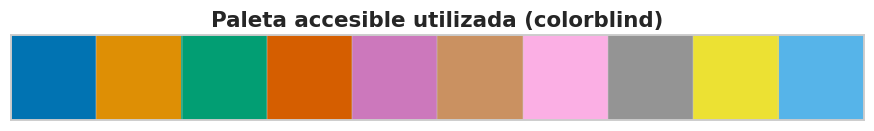

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
paleta = sns.color_palette("colorblind")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "grid.alpha": 0.35,
})
sns.palplot(paleta)
plt.title("Paleta accesible utilizada (colorblind)")
plt.show()

## 3. Gráfico categórico: promedio de cuenta por día

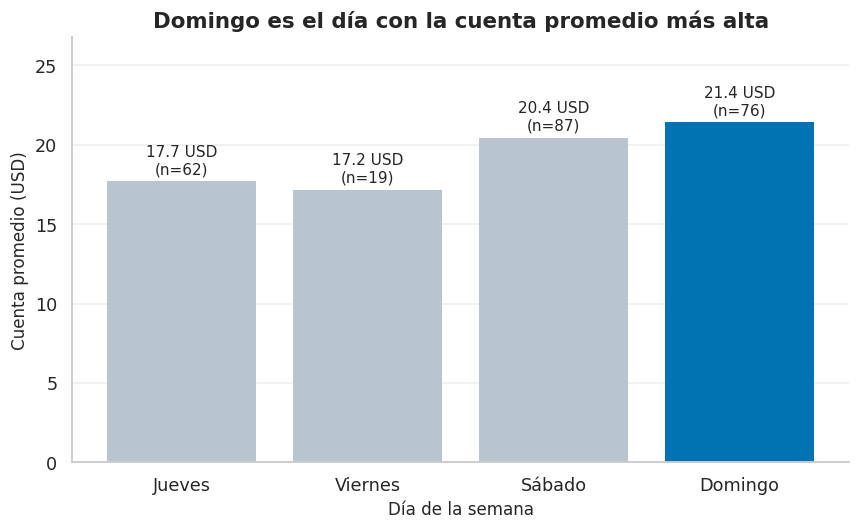

In [ ]:
resumen_dia = (tips.groupby("day", observed=True)
                    .agg(cuenta_prom=("total_bill", "mean"), n=("total_bill", "size"))
                    .reset_index())

fig, ax = plt.subplots(figsize=(8, 5))
# Se resalta el día con mayor promedio; el resto queda en un tono neutro (atención selectiva)
mayor = resumen_dia["cuenta_prom"].idxmax()
colores = [paleta[0] if i == mayor else "#B8C4CE" for i in range(len(resumen_dia))]

barras = ax.bar(resumen_dia["day"].astype(str), resumen_dia["cuenta_prom"], color=colores, edgecolor="none")
ax.bar_label(barras, labels=[f"{v:.1f} USD\n(n={n})" for v, n in zip(resumen_dia["cuenta_prom"], resumen_dia["n"])],
             padding=3, fontsize=10)

ax.set_title("Domingo es el día con la cuenta promedio más alta")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Cuenta promedio (USD)")
ax.set_ylim(0, resumen_dia["cuenta_prom"].max() * 1.25)
ax.set_xticks(range(4))
ax.set_xticklabels(["Jueves", "Viernes", "Sábado", "Domingo"])
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.show()



- **Tipo de dato:** variable categórica ordinal (`day`) frente a una medida numérica agregada (promedio de `total_bill`).
- **Por qué barras:** el ojo humano compara con precisión **longitudes sobre una misma línea base**, por lo que las barras son la forma más eficaz para comparar categorías. Un gráfico de pastel dificultaría comparar 4 categorías de valores parecidos.
- **Color:** se aplica el principio de **énfasis mediante contraste**: una sola barra en azul saturado (la más alta) y las demás en gris neutro. Esto guía la atención al hallazgo principal sin necesidad de leyenda.
- **Disposición:** eje Y desde cero (para no exagerar diferencias), orden cronológico de los días, valores escritos sobre cada barra y el tamaño de muestra `n` para evitar sobreinterpretar días con pocos datos. Sin cuadrícula vertical ni bordes innecesarios.
- **Título:** afirma la conclusión (título informativo) en lugar de solo describir el gráfico.

## 4. Gráfico numérico: relación entre cuenta y propina (dispersión)

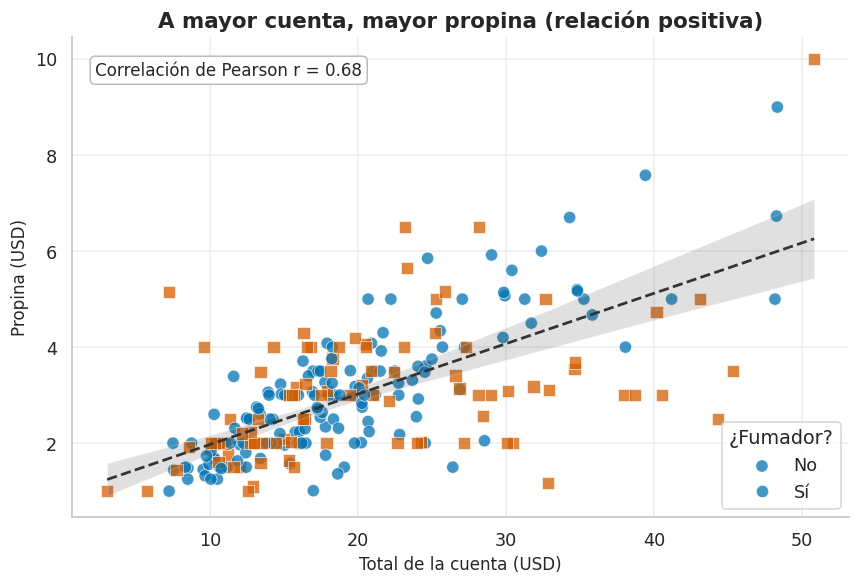

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.scatterplot(data=tips, x="total_bill", y="tip", hue="smoker",
                hue_order=["No", "Yes"], palette=[paleta[0], paleta[3]],
                style="smoker", markers={"No": "o", "Yes": "s"},
                s=65, alpha=0.75, edgecolor="white", linewidth=0.5, ax=ax)

# Línea de tendencia global
sns.regplot(data=tips, x="total_bill", y="tip", scatter=False, color="#333333",
            line_kws={"linewidth": 1.8, "linestyle": "--"}, ci=95, ax=ax)

r = tips["total_bill"].corr(tips["tip"])
ax.text(0.03, 0.95, f"Correlación de Pearson r = {r:.2f}", transform=ax.transAxes,
        fontsize=11, va="top", bbox=dict(boxstyle="round", fc="white", ec="#BBBBBB"))

ax.set_title("A mayor cuenta, mayor propina (relación positiva)")
ax.set_xlabel("Total de la cuenta (USD)")
ax.set_ylabel("Propina (USD)")
ax.legend(title="¿Fumador?", labels=["No", "Sí"], loc="lower right", frameon=True)
sns.despine()
plt.tight_layout()
plt.show()



- **Tipo de dato:** dos variables numéricas continuas (`total_bill` y `tip`) más una categórica (`smoker`).
- **Por qué dispersión:** es el gráfico adecuado para revelar **relaciones y correlación** entre dos variables cuantitativas; la posición en dos ejes es una de las codificaciones visuales más precisas.
- **Color y forma (redundancia):** los grupos se distinguen por **color (azul vs. naranja/rojo de la paleta colorblind) y por forma (círculo vs. cuadrado)**. Así el gráfico sigue siendo legible en escala de grises o para personas con daltonismo.
- **Disposición:** se usa transparencia (`alpha=0.75`) y bordes blancos para reducir el solapamiento de puntos; la línea de tendencia punteada resume el patrón sin competir con los datos; el valor de `r` se anota directamente en el gráfico.
- **Etiquetas:** ejes con unidades (USD), leyenda con título claro y ubicada en un área vacía del gráfico.

## 5. Gráfico temporal: evolución semanal de los ingresos

El dataset original **no contiene fechas**, así que se **simula una columna `date`**. Para que la simulación sea coherente, a cada registro se le asigna una fecha dentro de un periodo de 26 semanas (enero–junio de 2023) cuyo **día de la semana coincide con la columna `day`** original. Se fija una semilla para que los resultados sean reproducibles.

In [ ]:
rng = np.random.default_rng(42)
inicio = pd.Timestamp("2023-01-02")  # lunes
offset_dia = {"Thur": 3, "Fri": 4, "Sat": 5, "Sun": 6}
n_semanas = 26

semanas = rng.integers(0, n_semanas, size=len(tips))
tips["date"] = [inicio + pd.Timedelta(days=int(7 * s + offset_dia[d]))
                for s, d in zip(semanas, tips["day"].astype(str))]
tips["date"] = pd.to_datetime(tips["date"])

print(tips[["day", "date"]].head())
print("Rango de fechas:", tips["date"].min().date(), "->", tips["date"].max().date())

   day       date
0  Sun 2023-01-22
1  Sun 2023-05-28
2  Sun 2023-05-07
3  Sun 2023-03-26
4  Sun 2023-03-26
Rango de fechas: 2023-01-05 -> 2023-07-02


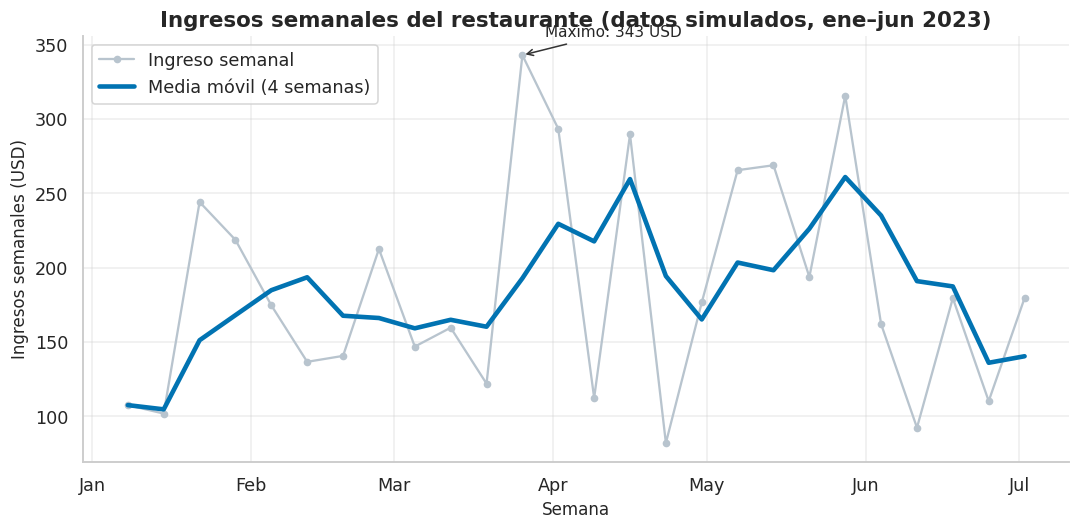

In [ ]:
# Ingresos (suma de cuentas) por semana, con semanas sin registros = 0
semanal = (tips.set_index("date")["total_bill"]
               .resample("W-SUN").sum()
               .rename("ingresos"))
semanal_df = semanal.reset_index()
semanal_df["media_movil"] = semanal_df["ingresos"].rolling(4, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(semanal_df["date"], semanal_df["ingresos"], color="#B8C4CE", marker="o",
        markersize=4, linewidth=1.5, label="Ingreso semanal")
ax.plot(semanal_df["date"], semanal_df["media_movil"], color=paleta[0],
        linewidth=3, label="Media móvil (4 semanas)")

# Anotación del punto máximo
i_max = semanal_df["ingresos"].idxmax()
ax.annotate(f"Máximo: {semanal_df.loc[i_max, 'ingresos']:.0f} USD",
            xy=(semanal_df.loc[i_max, "date"], semanal_df.loc[i_max, "ingresos"]),
            xytext=(15, 12), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#333333"), fontsize=10)

ax.set_title("Ingresos semanales del restaurante (datos simulados, ene–jun 2023)")
ax.set_xlabel("Semana")
ax.set_ylabel("Ingresos semanales (USD)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
ax.legend(loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()


- **Tipo de dato:** serie temporal (fecha simulada) frente a una medida numérica (suma de `total_bill` por semana).
- **Por qué líneas:** la conexión entre puntos consecutivos transmite **continuidad y tendencia** en el tiempo, algo que las barras o los puntos aislados comunican peor.
- **Jerarquía visual:** la serie semanal, ruidosa, se dibuja en gris claro (contexto) y la **media móvil** en azul grueso (mensaje principal). Es el mismo principio de contraste usado en el gráfico 1: el color intenso se reserva para lo importante.
- **Disposición:** eje X con meses abreviados (menos saturación que 26 fechas), una única anotación para el máximo y leyenda en la esquina superior izquierda.
- **Transparencia sobre los datos:** el título aclara que la fecha es **simulada**, para no inducir a conclusiones reales sobre estacionalidad.

## 6. Gráfico adicional: distribución del porcentaje de propina por día y turno (boxplot)

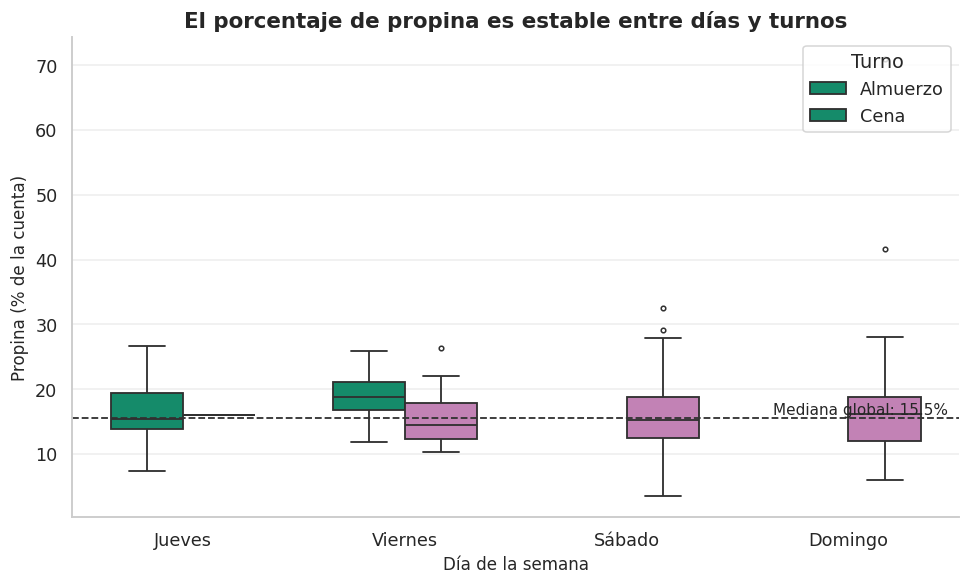

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.boxplot(data=tips, x="day", y="tip_pct", hue="time",
            hue_order=["Lunch", "Dinner"], palette=[paleta[2], paleta[4]],
            width=0.65, linewidth=1.2, fliersize=3, ax=ax)

# Mediana global como línea de referencia
mediana = tips["tip_pct"].median()
ax.axhline(mediana, color="#333333", linestyle="--", linewidth=1.2)
ax.text(3.45, mediana + 0.6, f"Mediana global: {mediana:.1f}%", ha="right", fontsize=10)

ax.set_title("El porcentaje de propina es estable entre días y turnos")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Propina (% de la cuenta)")
ax.set_xticks(range(4))
ax.set_xticklabels(["Jueves", "Viernes", "Sábado", "Domingo"])
ax.legend(title="Turno", labels=["Almuerzo", "Cena"], loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Verificación numérica de lo que muestra el boxplot
tips.groupby(["day", "time"], observed=True)["tip_pct"].agg(["count", "median", "mean"]).round(1)

count  median  mean
day  time                       
Thur Lunch      61    15.4  16.1
     Dinner      1    16.0  16.0
Fri  Lunch       7    18.8  18.9
     Dinner     12    14.5  15.9
Sat  Dinner     87    15.2  15.3
Sun  Dinner     76    16.1  16.7


- **Tipo de dato:** variable numérica continua (`tip_pct`, variable derivada) segmentada por dos categóricas (`day` y `time`).
- **Por qué boxplot:** las barras de promedios ocultan la dispersión. El boxplot muestra **mediana, cuartiles y valores atípicos**, permitiendo comparar distribuciones completas entre grupos. Se eligió el porcentaje de propina (y no la propina en USD) para **normalizar** por el tamaño de la cuenta y comparar de forma justa.
- **Color:** dos tonos de la paleta accesible (verde y morado) claramente distinguibles entre sí y distintos a los usados antes, evitando reutilizar el mismo color para significados diferentes.
- **Disposición:** la línea punteada de la mediana global da un punto de referencia común; la leyenda se ubica arriba a la derecha, donde hay espacio libre.
- **Nota:** el jueves es casi todo almuerzo (61 de 62 registros), y sábado y domingo solo tienen cenas; por eso algunas cajas faltan o se basan en pocos datos (ver tabla anterior). El viernes tiene solo 19 registros, así que sus medianas son menos fiables.

## 7. Conclusión del análisis

En conclusion el  análisis del dataset me permitió identificar los siguientes:

1. **Día de la semana:** el domingo presenta la cuenta promedio más alta (≈ 21.4 USD), seguido del sábado (≈ 20.4 USD), mientras que jueves y viernes rondan los 17 USD; los fines de semana concentran también la mayor parte de los registros (163 de 244).
2. **Relación cuenta-propina:** existe una **correlación positiva fuerte** (r ≈ 0.68): a mayor cuenta, mayor propina en dólares. La dispersión aumenta con cuentas altas, lo que indica que la propina no siempre crece de forma proporcional. No se observan diferencias claras entre fumadores y no fumadores (mediana de propina ≈ 15.4 % vs. 15.6 %).
3. **Comportamiento en el tiempo (simulado):** la serie semanal es irregular y la media móvil suaviza esas fluctuaciones. Como las fechas fueron generadas artificialmente, este gráfico sirve para practicar la visualización temporal, **no** para extraer conclusiones reales de estacionalidad.
4. **Porcentaje de propina:** medido como proporción de la cuenta, la propina es bastante **estable (mediana global ≈ 15.5 %)** entre días y turnos; la variación en dólares se explica sobre todo por el monto de la cuenta, y no por el día o el turno.

**Sobre el diseño:** el uso consistente de una paleta accesible, el color de énfasis sobre fondos neutros, los títulos informativos y la redundancia color-forma hicieron que cada gráfico comunique un mensaje principal sin saturación visual.